# Plot global gradients of main principal components 

In [11]:
!pwd



/net/home/swolf/Func_Neo_Phytes


In [12]:
# set working directory
import os
os.chdir("/net/home/swolf/Func_Neo_Phytes/")

### Load summary stats at hexagon level

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import h3pandas

In [14]:
summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree_group_with_CSR.csv")
summary_data.head()

,h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,...,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47,LA_resolved,C,S,R
0,83001afffffffff,all,-10.334354,1.322861,-1.725583,1.041462,2.158910,10,4,5.68,...,85.452,2.183,3.140,-0.547,0.333000,0.152,1.449,0.911566,0.000000,99.088434
1,83001afffffffff,native,-10.334354,1.322861,-1.725583,1.041462,2.158910,10,4,5.68,...,85.452,2.183,3.140,-0.547,0.333000,0.152,1.449,0.911566,0.000000,99.088434
2,83001cfffffffff,all,-10.005360,-0.238006,0.249138,2.913739,0.975752,1,1,16.22,...,92.099,2.545,3.121,-0.563,0.316611,0.175,1.518,2.943733,19.720529,77.335738
3,83001cfffffffff,native,-9.988809,-0.301432,0.282222,2.913640,0.966630,1,1,16.22,...,92.099,2.545,3.121,-0.563,0.329122,0.175,1.518,2.943733,19.720529,77.335738
4,83001efffffffff,all,-10.690103,-0.871359,-0.945247,-0.268565,1.311954,4,3,3.38,...,88.269,2.311,3.671,-1.933,0.409000,0.211,1.391,0.000000,47.807063,52.192937


## Map hexagons

### Create GeoDataFrame and Clean Geometries

This code block converts H3 hexagon indices to polygons, wraps longitudes to the range [-180, 180], and creates a GeoDataFrame. Invalid geometries and polygons spanning more than 180° longitude are removed to ensure clean and accurate spatial data for further analysis.




In [15]:
final_df = summary_data.copy()

In [16]:
import geopandas as gpd
import h3
from shapely.geometry import Polygon
from shapely.ops import transform
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Function to convert H3 cell to polygon
def h3_to_polygon(h3_index):
    boundary = h3.h3_to_geo_boundary(h3_index, geo_json=True)
    return Polygon(boundary)

# Function to wrap longitudes to [-180, 180]
def wrap_geometry(geom):
    def wrap_coords(x, y):
        x_wrapped = ((x + 180) % 360) - 180
        return x_wrapped, y
    return transform(lambda x, y: wrap_coords(x, y), geom)

# Build geometry column
final_df["geometry"] = final_df["h3_res3"].apply(lambda x: wrap_geometry(h3_to_polygon(x)))

# Create GeoDataFrame
gdf = gpd.GeoDataFrame(final_df, geometry="geometry", crs="EPSG:4326")

# Fix column names
gdf.columns = gdf.columns.str.replace('.', '_')

# 💥 Remove invalid geometries and those spanning too much longitude
gdf = gdf[gdf.geometry.is_valid]  # remove invalid
gdf = gdf[gdf.bounds.maxx - gdf.bounds.minx < 180]  # remove polygons >180° wide


/tmp/ipykernel_95540/3219989185.py:28: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  gdf.columns = gdf.columns.str.replace('.', '_')


### Plot world map 

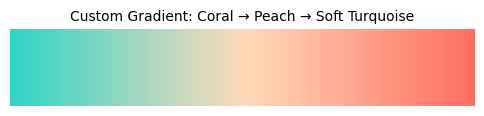

In [17]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Define your custom colors
colors = [ "#2ed5c9", "#FFDAB9", "#FF6F61"]

# Create the colormap
native_non_cmap = mcolors.LinearSegmentedColormap.from_list("custom_gradient", colors)

# OPTIONAL: Visualize it with a gradient bar
gradient = np.linspace(0, 1, 256).reshape(1, -1)

plt.figure(figsize=(6, 1))

plt.imshow(gradient, aspect='auto', cmap=native_non_cmap)
plt.axis("off")
plt.title("Custom Gradient: Coral → Peach → Soft Turquoise", fontsize=10)
plt.show()


In [18]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Define your colors
low_color = "#2F86AC"      # like native_color
mid_color = "white"
high_color = "#b02f2c"     # like all_color

# Create a custom diverging colormap
div_cmap = mcolors.LinearSegmentedColormap.from_list(
    "custom_diverging",
    [low_color, mid_color, high_color]
)


In [19]:
def plot_maps(gdf, pattern, output_suffix="meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted"):
    
    import os
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    os.makedirs("Results/Figures", exist_ok=True)

    # Loop over columns matching the pattern
    for column in [col for col in gdf.columns if col.startswith(pattern)]:

        # -------------------------
        # Set colour scale
        # -------------------------

        if "percent_change" in column:
            vmin, vmax = -80, 80
            cmap = div_cmap

        elif "rank_biserial_r" in column:
            vmin, vmax = -0.7, 0.7
            cmap = div_cmap

        elif "perc_naturalized" in column:
            vmin, vmax = 0, 100
            cmap = "YlGnBu"

        elif "conifer_percentage" in column:
            vmin, vmax = 0, 20
            cmap = "YlGnBu"

        elif "annual_percentage" in column:
            vmin, vmax = 0, 40
            cmap = "YlGnBu_r"

        elif "PC1_diff" in column:
            vmin = np.nanpercentile(gdf[column], 5)
            vmax = np.nanpercentile(gdf[column], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC2_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC3_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC4_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC5_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif any(x in column for x in ["urban_diff", "nat_diff", "crop_diff"]):
            vmin, vmax = -1, 1
            cmap = div_cmap

        else:
            vmin = np.nanpercentile(gdf[column], 1)
            vmax = np.nanpercentile(gdf[column], 99)
            cmap = "YlGnBu"

        # -------------------------
        # Create map
        # -------------------------

        fig, ax = plt.subplots(
            figsize=(12, 10),
            subplot_kw={"projection": ccrs.EqualEarth()}
        )

        ax.set_global()

        ax.add_feature(
            cfeature.LAND,
            facecolor="#afafafff",
            edgecolor="none"
        )

        ax.add_feature(
            cfeature.OCEAN,
            facecolor="#dad8eaff",
            edgecolor="none"
        )

        ax._autoscaleXon = True
        ax._autoscaleYon = True

        # Plot hexagons
        gdf.plot(
            column=column,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            legend=True,
            ax=ax,
            transform=ccrs.PlateCarree(),
            linewidth=0.001,
            legend_kwds={"shrink": 0.45}
        )

        ax.set_title(
            f"{column} per hexagon",
            fontsize=12
        )

        for spine in ax.spines.values():
            spine.set_edgecolor("#dad8eaff")
            spine.set_linewidth(0.7)

        plt.tight_layout()

        # -------------------------
        # Save
        # -------------------------

        output_path = (
            f"Results/Figures/"
            f"{column}_{output_suffix}.png"
        )

        plt.savefig(
            output_path,
            dpi=500,
            bbox_inches="tight"
        )
        print(output_path)
        plt.show()
        plt.close()

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

Results/Figures/C_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


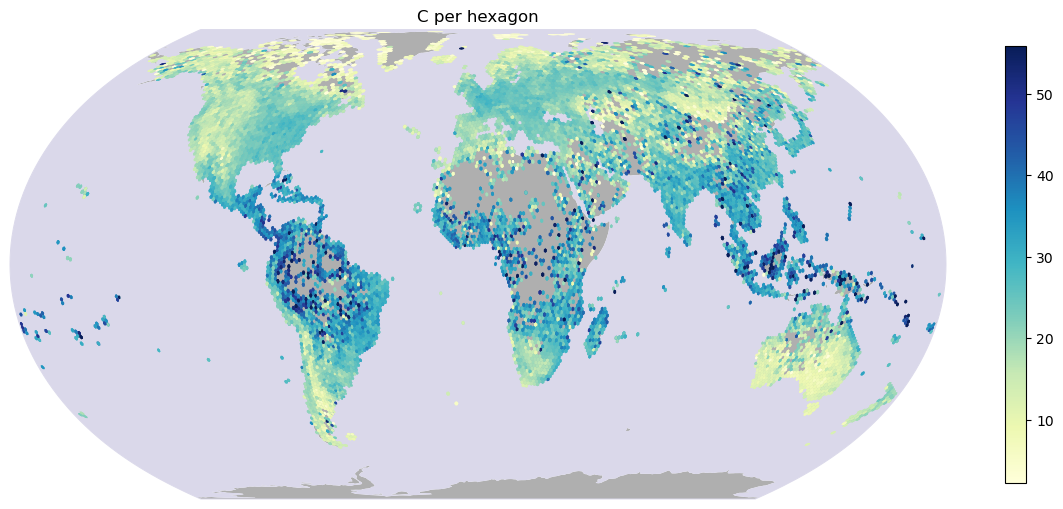

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/S_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


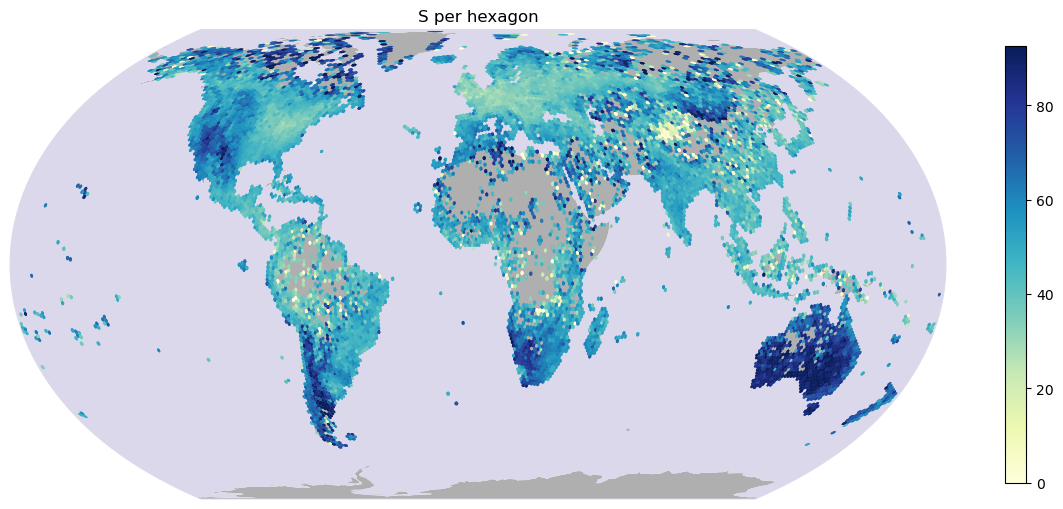

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/R_meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted.png


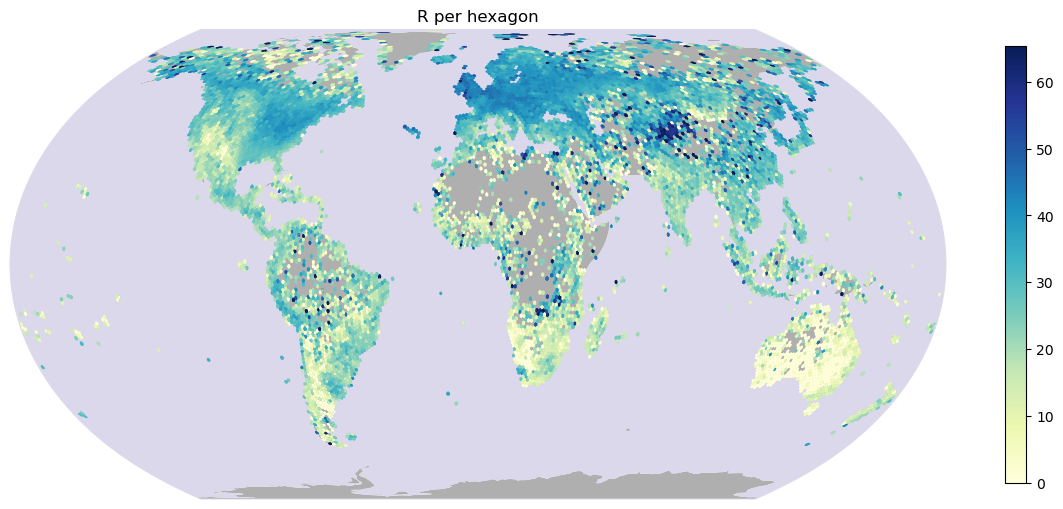

In [10]:
# Plot PC axes 1-5 for all and native

plot_maps(gdf, "C")
plot_maps(gdf, "S")
plot_maps(gdf, "R")

## RGB map

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

Results/Figures/CSR_native_rgb_stretched.png


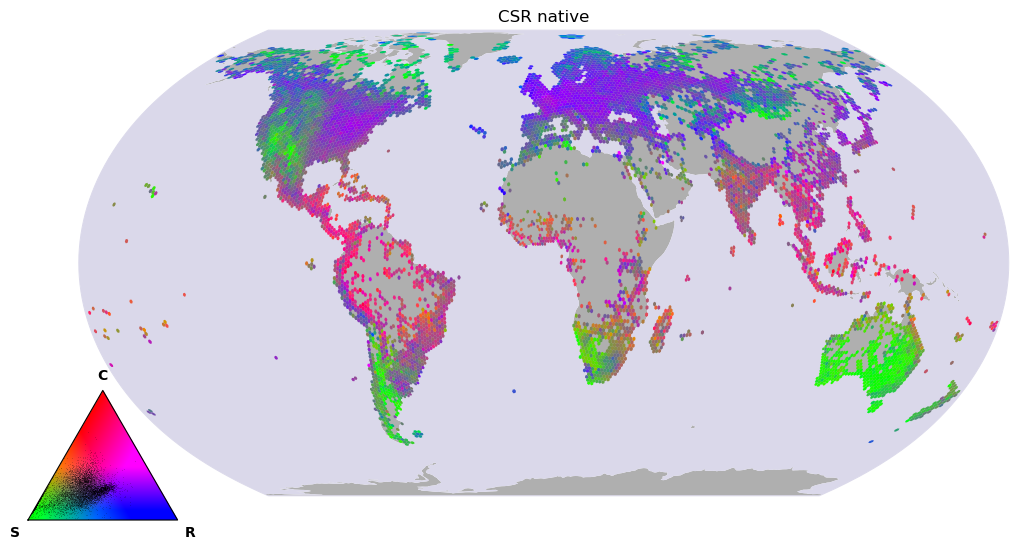

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

Results/Figures/CSR_all_rgb_stretched.png


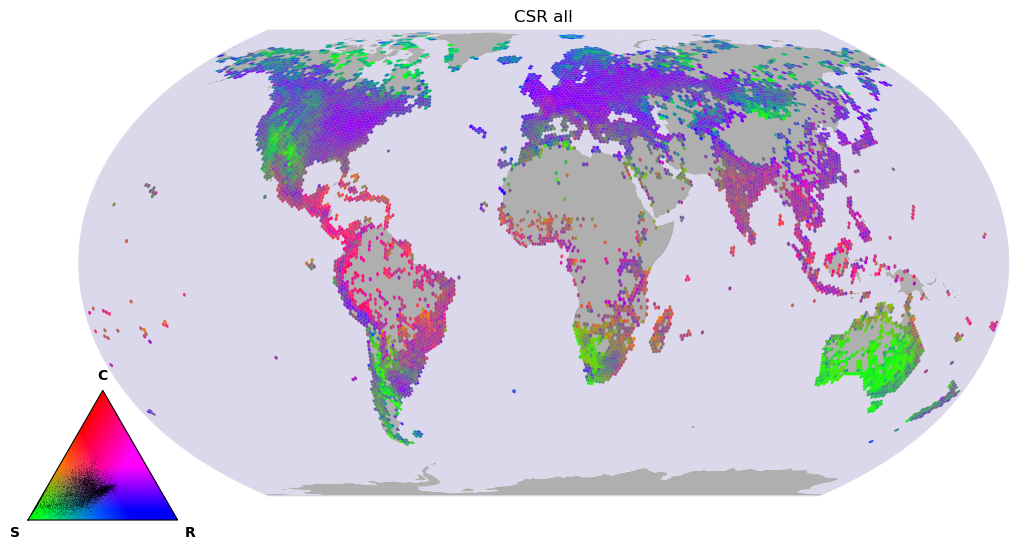

In [26]:
import pandas as pd
import geopandas as gpd
import h3
from shapely.geometry import Polygon

# ── 1. Long → wide: one row per hexagon ──────────────────────────────────────
wide = summary_data.pivot(index="h3_res3", columns="group", values=["C", "S", "R", "count_sp"])
wide.columns = [f"{var}_{grp}" for var, grp in wide.columns]   # → C_all, C_native, ...
wide = wide.reset_index()

# ── 2. Hexagon polygons ──────────────────────────────────────────────────────
def hex_polygon(cell):
    if hasattr(h3, "cell_to_boundary"):                    # h3 v4
        return Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(cell)])
    return Polygon(h3.h3_to_geo_boundary(cell, geo_json=True))   # h3 v3: already (lng, lat)

gdf = gpd.GeoDataFrame(wide, geometry=wide["h3_res3"].apply(hex_polygon), crs="EPSG:4326")

# Drop hexagons crossing the antimeridian (they'd smear across the whole map)
gdf = gdf[(gdf.geometry.bounds["maxx"] - gdf.geometry.bounds["minx"]) < 180]

# ── 3. Drop species-poor hexagons ────────────────────────────────────────────
gdf = gdf[(gdf["count_sp_native"] >= 10) & (gdf["count_sp_all"] >= 10)]

# ── 4. Plot (functions from before) ──────────────────────────────────────────
cols_native = ("C_native", "S_native", "R_native")
cols_all    = ("C_all",    "S_all",    "R_all")

lims = stretch_limits(gdf, [cols_native, cols_all])
plot_csr_rgb(gdf, cols_native, lims, "CSR native", "rgb_stretched")
plot_csr_rgb(gdf, cols_all,    lims, "CSR all",    "rgb_stretched")

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

Results/Figures/CSR_native_rgb_stretched.png


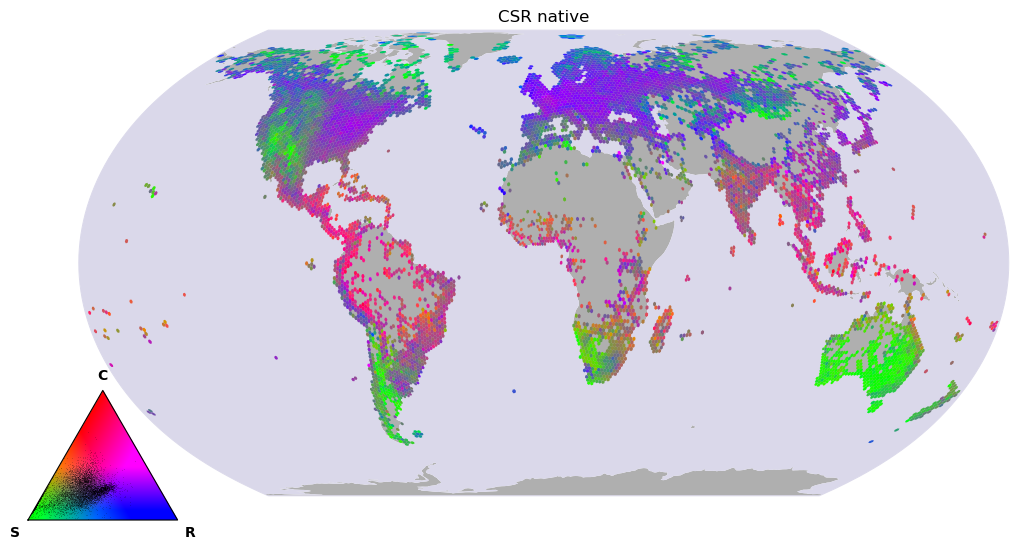

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

Results/Figures/CSR_all_rgb_stretched.png


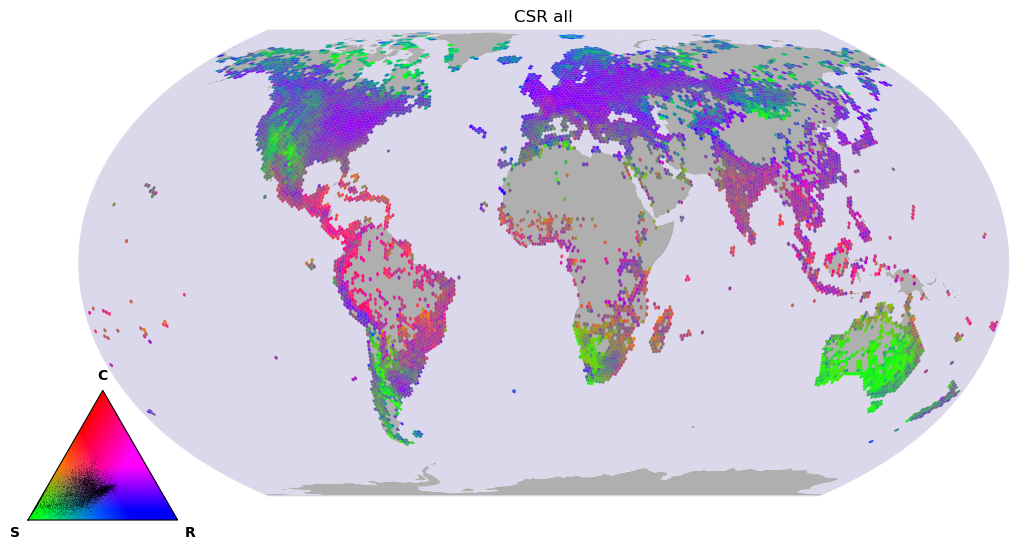

In [25]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature


def csr_to_rgb(C, S, R, lims=None):
    """C, S, R in % → N×3 RGB (C=red, S=green, R=blue).
    lims=(lo, hi): per-channel stretch, arrays of length 3 in 0–1 units."""
    rgb = np.column_stack([C, S, R]).astype(float) / 100
    if lims is not None:
        lo, hi = lims
        rgb = (rgb - lo) / (hi - lo)
    return np.clip(rgb, 0, 1)


def stretch_limits(gdf, col_sets, q=(2, 98)):
    """Shared stretch across several maps (e.g. native + all) so colours are comparable."""
    vals = np.vstack([gdf[list(cols)].to_numpy(float) for cols in col_sets]) / 100
    return (np.nanpercentile(vals, q[0], axis=0),
            np.nanpercentile(vals, q[1], axis=0))


def ternary_legend(ax, lims, data=None, res=300):
    """Coloured CSR triangle (C top, S bottom-left, R bottom-right) + data points."""
    h = np.sqrt(3) / 2
    X, Y = np.meshgrid(np.linspace(0, 1, res), np.linspace(0, h, res))
    c = Y / h
    r = X - 0.5 * c
    s = 1 - c - r
    inside = (c >= 0) & (r >= 0) & (s >= 0)
    rgb = csr_to_rgb(c.ravel() * 100, s.ravel() * 100, r.ravel() * 100, lims).reshape(res, res, 3)
    ax.imshow(np.dstack([rgb, inside.astype(float)]), origin="lower", extent=(0, 1, 0, h))

    if data is not None:   # where the hexagons actually fall
        d = data[~np.isnan(data).any(axis=1)] / 100
        ax.scatter(0.5 * d[:, 0] + d[:, 2], h * d[:, 0],
                   s=0.4, c="k", alpha=0.15, linewidths=0, rasterized=True)

    ax.plot([0, 1, 0.5, 0], [0, 0, h, 0], c="k", lw=0.8)
    ax.text(0.5, h + 0.05, "C", ha="center", va="bottom", fontweight="bold")
    ax.text(-0.05, -0.04, "S", ha="right", va="top", fontweight="bold")
    ax.text(1.05, -0.04, "R", ha="left", va="top", fontweight="bold")
    ax.set_xlim(-0.12, 1.12); ax.set_ylim(-0.12, h + 0.15)
    ax.set_aspect("equal"); ax.axis("off")


def plot_csr_rgb(gdf, cols, lims, title, output_suffix):
    os.makedirs("Results/Figures", exist_ok=True)
    g = gdf.dropna(subset=list(cols))
    rgb = csr_to_rgb(*(g[c].to_numpy() for c in cols), lims)

    fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={"projection": ccrs.EqualEarth()})
    ax.set_global()
    ax._autoscaleXon = True
    ax._autoscaleYon = True
    ax.add_feature(cfeature.LAND, facecolor="#afafafff", edgecolor="none")
    ax.add_feature(cfeature.OCEAN, facecolor="#dad8eaff", edgecolor="none")

    g.plot(color=rgb, ax=ax, transform=ccrs.PlateCarree(), linewidth=0)

    for spine in ax.spines.values():
        spine.set_edgecolor("#dad8eaff"); spine.set_linewidth(0.7)
    ax.set_title(title, fontsize=12)

    leg = fig.add_axes([0.06, 0.22, 0.17, 0.17])   # adjust position as needed
    ternary_legend(leg, lims, data=g[list(cols)].to_numpy(float))

    out = f"Results/Figures/{title.replace(' ', '_')}_{output_suffix}.png"
    plt.savefig(out, dpi=500, bbox_inches="tight")
    print(out)
    plt.show()
    plt.close()


# ── Usage: adjust column names to yours ──────────────────────────────────────
cols_native = ("C_native", "S_native", "R_native")
cols_all    = ("C_all",    "S_all",    "R_all")

lims = stretch_limits(gdf, [cols_native, cols_all])   # one shared stretch

plot_csr_rgb(gdf, cols_native, lims, "CSR native", "rgb_stretched")
plot_csr_rgb(gdf, cols_all,    lims, "CSR all",    "rgb_stretched")